In [ ]:
# IMPORTANT: SOME KAGGLE DATA SOURCES ARE PRIVATE
# RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES.
import kagglehub
kagglehub.login()


In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.

khairulfikri15_chili_leaf_deases_path = kagglehub.dataset_download('khairulfikri15/chili-leaf-deases')

print('Data source import complete.')


In [ ]:
# Setup dan Konfigurasi
import os, io, json, time, copy, random, hashlib, platform, warnings
from pathlib import Path
from dataclasses import dataclass, asdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.manifold import TSNE
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, silhouette_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")


@dataclass
class Cfg:
    seed: int = 42
    img_size: int = 224          # resolusi input jaringan
    cache_size: int = 256        # resolusi cache RAM (sumber random crop)
    batch_size: int = 32
    epochs_p1: int = 10          # fase 1: feature extraction
    epochs_p2: int = 20          # fase 2: fine-tuning
    lr_p1: float = 1e-3
    lr_p2: float = 1e-4
    weight_decay: float = 1e-4
    dropout: float = 0.3
    ft_blocks: int = 5           # jumlah blok `features` teratas yang dibuka saat fine-tuning
    patience: int = 5            # early stopping (val loss)
    n_splits: int = 7            # 1/7 ≈ 14,3% -> split ≈ 71/14/14
    hash_thr: int = 4            # ambang Hamming dHash untuk near-duplicate
    n_boot: int = 1000           # resampling bootstrap untuk CI 95%


cfg = Cfg()
PREFERRED_DIR = ("/kaggle/input/datasets/khairulfikri15/chili-leaf-deases/"
                 "Chili Leaf Disease Original Dataset")
OUT = Path("/kaggle/working")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"


def set_seed(seed: int) -> None:
    """Set seluruh sumber keacakan agar eksperimen dapat direproduksi."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def savefig(name: str) -> None:
    plt.savefig(OUT / "figures" / f"{name}.png", dpi=300, bbox_inches="tight")


set_seed(cfg.seed)
ENV = {"python": platform.python_version(), "torch": torch.__version__,
       "device": torch.cuda.get_device_name(0) if USE_AMP else "cpu",
       "cuda": torch.version.cuda, "amp": USE_AMP}
print(pd.Series(ENV).to_string(), "\n")
print(pd.Series(asdict(cfg)).to_string())

python         3.13.16
torch     2.11.0+cu130
device        Tesla T4
cuda              13.0
amp               True 

seed              42.0000
img_size         224.0000
cache_size       256.0000
batch_size        32.0000
epochs_p1         10.0000
epochs_p2         20.0000
lr_p1              0.0010
lr_p2              0.0001
weight_decay       0.0001
dropout            0.3000
ft_blocks          5.0000
patience           5.0000
n_splits           7.0000
hash_thr           4.0000
n_boot          1000.0000


In [ ]:
# Lokasi dataset & audit per-file
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def locate_dataset(preferred: str) -> Path:
    """Gunakan path utama; jika tidak ada, maka cari folder dengan nama yang sama."""
    if Path(preferred).is_dir():
        return Path(preferred)
    for root, _, _ in os.walk("/kaggle/input"):
        if Path(root).name == "Chili Leaf Disease Original Dataset":
            return Path(root)
    raise FileNotFoundError("Folder dataset tidak ditemukan; cek Add Input.")


def inspect_image(path: str) -> dict:
    """Validasi file, ukuran asli, MD5 (duplikat persis), dan dHash 64-bit (near-duplicate)."""
    rec = {"path": path, "valid": False}
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            rec["width"], rec["height"] = im.size
            im.draft("L", (160, 160))                     # percepat decode JPEG
            g = np.asarray(im.convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
        rec["dhash"] = (g[:, 1:] > g[:, :-1]).flatten().astype(np.uint8)
        rec["md5"] = hashlib.md5(Path(path).read_bytes()).hexdigest()
        rec["valid"] = True
    except Exception as e:
        rec["error"] = str(e)
    return rec


DATA_DIR = locate_dataset(PREFERRED_DIR)
class_names = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)

rows = [(str(p), c) for c in class_names
        for p in sorted((DATA_DIR / c).rglob("*")) if p.suffix.lower() in IMG_EXT]
df_raw = pd.DataFrame(rows, columns=["path", "label_name"])
df_raw["label"] = df_raw.label_name.map(class_to_idx)

with ThreadPoolExecutor(4) as ex:
    meta = pd.DataFrame(list(ex.map(inspect_image, df_raw.path)))
df_raw = df_raw.merge(meta, on="path")

print("DATA_DIR:", DATA_DIR)
print("Kelas   :", class_names)
print("Total   :", len(df_raw), "| rusak:", int((~df_raw.valid).sum()))
print(df_raw[df_raw.valid][["width", "height"]].describe().loc[["min", "50%", "max"]].round(0).to_string())

DATA_DIR: /kaggle/input/datasets/khairulfikri15/chili-leaf-deases/Chili Leaf Disease Original Dataset
Kelas   : ['Bacterial Spot', 'Cercospora Leaf Spot', 'Curl Virus', 'Healthy Leaf', 'Nutrition Deficiency', 'White spot']
Total   : 1856 | rusak: 0
      width  height
min  1000.0  1000.0
50%  1000.0  1000.0
max  1000.0  1000.0


In [ ]:
# Pembersihan data & pengelompokan near-duplicate
def clean_dataset(df: pd.DataFrame, thr: int):
    """Buang file rusak, hash berlabel konflik, duplikat persis; beri `group` untuk near-duplicate."""
    log = {"awal": len(df)}
    df = df[df.valid].copy()
    log["rusak"] = log["awal"] - len(df)

    # hash identik dengan label berbeda -> label tidak dapat dipercaya, buang semua salinan
    nlab = df.groupby("md5").label.nunique()
    conflict = nlab[nlab > 1].index
    n = len(df); df = df[~df.md5.isin(conflict)]
    log["hash_label_konflik"] = len(conflict)
    log["file_label_konflik_dibuang"] = n - len(df)

    n = len(df); df = df.drop_duplicates("md5").reset_index(drop=True)
    log["duplikat_persis"] = n - len(df)

    # near-duplicate: jarak Hamming dHash <= thr, digabung dengan union-find
    H = np.stack(df.dhash.values).astype(np.float32)
    dist = 64 - (H @ H.T + (1 - H) @ (1 - H).T)
    ii, jj = np.where(np.triu(dist <= thr, k=1))
    parent = np.arange(len(df))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]; i = parent[i]
        return i

    for i, j in zip(ii, jj):
        parent[find(i)] = find(j)
    df["group"] = [find(i) for i in range(len(df))]

    sizes = df.group.value_counts()
    log["pasangan_near_dup"] = int(len(ii))
    log["pasangan_near_dup_lintas_kelas"] = int((df.label.values[ii] != df.label.values[jj]).sum())
    log["klaster_near_dup"] = int((sizes > 1).sum())
    log["gambar_dalam_klaster"] = int(sizes[sizes > 1].sum())
    log["akhir"] = len(df)
    return df.drop(columns=["dhash", "valid"]), log


df, clean_log = clean_dataset(df_raw, cfg.hash_thr)
print(pd.Series(clean_log).to_string())

awal                              1856
rusak                                0
hash_label_konflik                   5
file_label_konflik_dibuang          14
duplikat_persis                      0
pasangan_near_dup                  599
pasangan_near_dup_lintas_kelas       0
klaster_near_dup                   303
gambar_dalam_klaster               771
akhir                             1842


label_name
Bacterial Spot          147
Cercospora Leaf Spot    175
Curl Virus              423
Healthy Leaf            458
Nutrition Deficiency    444
White spot              195 
Rasio ketimpangan (maks/min): 3.12


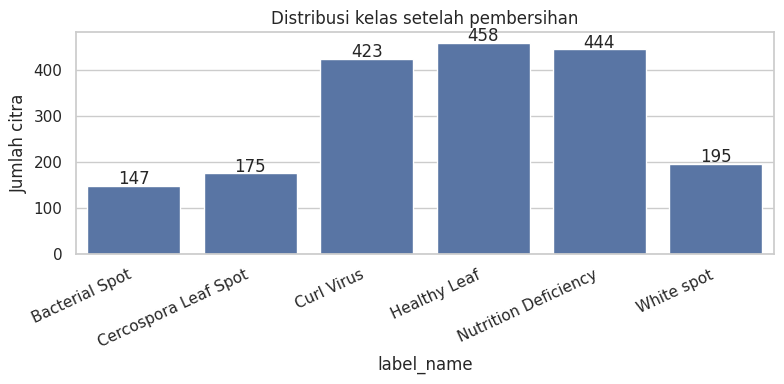

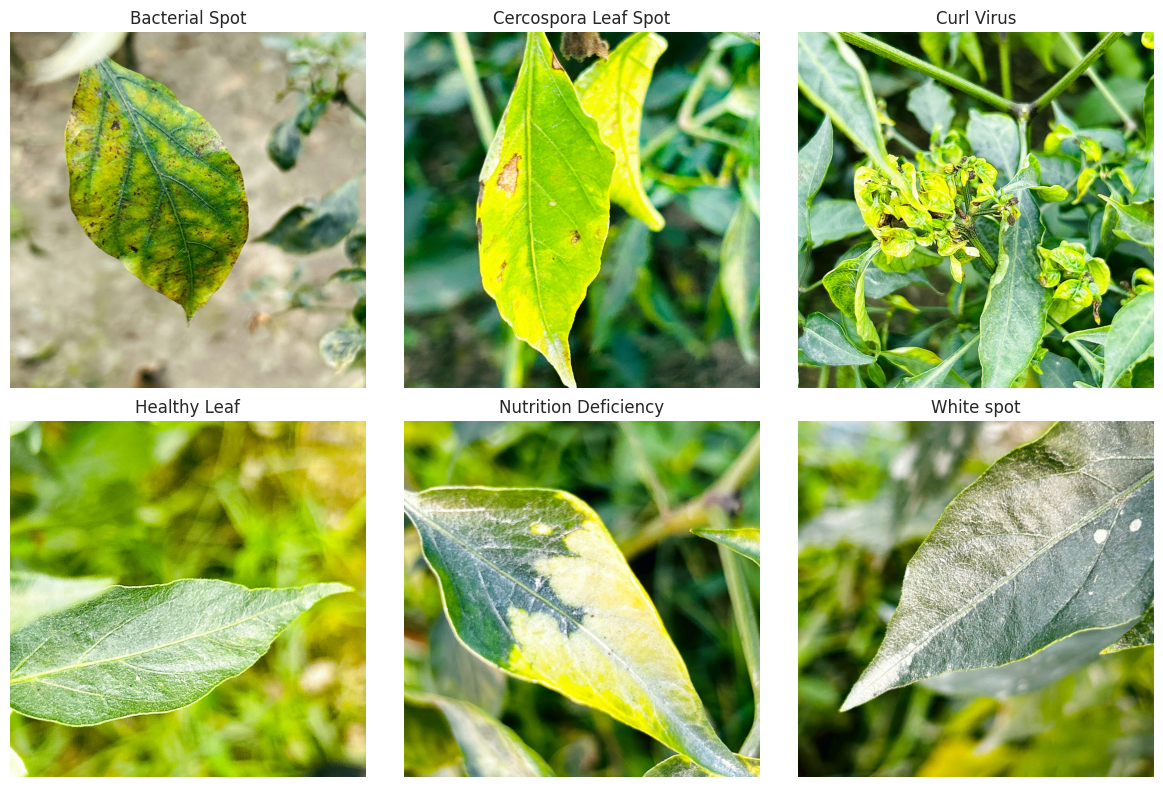

In [ ]:
# =Distribusi kelas & contoh citra
dist = df.label_name.value_counts().reindex(class_names)
imb = dist.max() / dist.min()
print(dist.to_string(), f"\nRasio ketimpangan (maks/min): {imb:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=dist.index, y=dist.values, color="#4C72B0", ax=ax)
for i, v in enumerate(dist.values):
    ax.text(i, v + 4, str(v), ha="center")
ax.set(ylabel="Jumlah citra", title="Distribusi kelas setelah pembersihan")
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); savefig("01_distribusi_kelas"); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, c in zip(axes.ravel(), class_names):
    p = df[df.label_name == c].sample(1, random_state=cfg.seed).path.iloc[0]
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(c); ax.axis("off")
plt.tight_layout(); savefig("02_contoh_citra"); plt.show()

In [ ]:
# Split stratified-group & class weight
def split_data(df: pd.DataFrame, n_splits: int, seed: int):
    """Test = 1 fold dari n_splits; val = 1 fold dari (n_splits-1) sisa. Near-duplicate tidak terpisah."""
    outer = StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed)
    trval_idx, test_idx = next(outer.split(df, df.label, df.group))
    trval = df.iloc[trval_idx].reset_index(drop=True)
    inner = StratifiedGroupKFold(n_splits - 1, shuffle=True, random_state=seed)
    tr_idx, val_idx = next(inner.split(trval, trval.label, trval.group))
    return (trval.iloc[tr_idx].reset_index(drop=True),
            trval.iloc[val_idx].reset_index(drop=True),
            df.iloc[test_idx].reset_index(drop=True))


train_df, val_df, test_df = split_data(df, cfg.n_splits, cfg.seed)

for a, b, n in [(train_df, val_df, "train-val"), (train_df, test_df, "train-test"), (val_df, test_df, "val-test")]:
    assert not set(a.path) & set(b.path), f"Overlap file {n}"
    assert not set(a.group) & set(b.group), f"Overlap grup near-duplicate {n}"

split_summary = pd.DataFrame({"train": train_df.label_name.value_counts(),
                              "val": val_df.label_name.value_counts(),
                              "test": test_df.label_name.value_counts()}).reindex(class_names)
split_summary.loc["TOTAL"] = split_summary.sum()
print(split_summary.to_string())
print("Proporsi:", (split_summary.loc["TOTAL"] / len(df)).round(3).to_dict())

# bobot kelas dihitung hanya dari data latih
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df.label.values)
cw_tensor = torch.tensor(cw, dtype=torch.float32, device=DEVICE)
print({c: round(float(w), 3) for c, w in zip(class_names, cw)})

                      train  val  test
label_name                            
Bacterial Spot          107   21    19
Cercospora Leaf Spot    121   24    30
Curl Virus              308   54    61
Healthy Leaf            323   70    65
Nutrition Deficiency    310   69    65
White spot              143   25    27
TOTAL                  1312  263   267
Proporsi: {'train': 0.712, 'val': 0.143, 'test': 0.145}
{'Bacterial Spot': 2.044, 'Cercospora Leaf Spot': 1.807, 'Curl Virus': 0.71, 'Healthy Leaf': 0.677, 'Nutrition Deficiency': 0.705, 'White spot': 1.529}


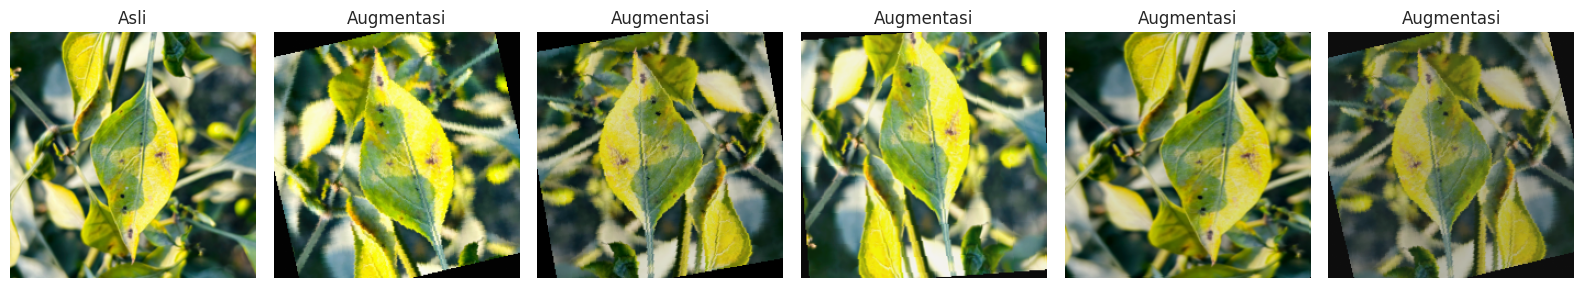

In [ ]:
# Cache RAM, transformasi, Dataset, DataLoader
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # statistik ImageNet

train_tf = T.Compose([
    T.RandomResizedCrop(cfg.img_size, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),  # tanpa hue: warna = cue gejala
    T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.Resize(cfg.img_size), T.ToTensor(), T.Normalize(MEAN, STD)])


def load_cache(paths, size):
    """Muat & resize sekali ke RAM agar training tidak terhambat decode JPEG resolusi besar."""
    def _load(p):
        with Image.open(p) as im:
            im.draft("RGB", (size * 2, size * 2))
            return im.convert("RGB").resize((size, size), Image.BILINEAR)
    with ThreadPoolExecutor(4) as ex:
        return list(ex.map(_load, paths))


class LeafDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self): return len(self.images)
    def __getitem__(self, i): return self.transform(self.images[i]), int(self.labels[i])


def seed_worker(_):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)


def make_loader(ds, shuffle, seed):
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=cfg.batch_size, shuffle=shuffle, num_workers=2,
                      pin_memory=True, worker_init_fn=seed_worker, generator=g)


train_imgs = load_cache(train_df.path, cfg.cache_size)
val_imgs = load_cache(val_df.path, cfg.cache_size)
test_imgs = load_cache(test_df.path, cfg.cache_size)
train_ds = LeafDataset(train_imgs, train_df.label.values, train_tf)
val_ds = LeafDataset(val_imgs, val_df.label.values, eval_tf)
test_ds = LeafDataset(test_imgs, test_df.label.values, eval_tf)

# visualisasi augmentasi (satu citra latih, 5 variasi)
denorm = lambda x: (x * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
axes[0].imshow(train_imgs[0].resize((cfg.img_size,) * 2)); axes[0].set_title("Asli")
for ax in axes[1:]:
    ax.imshow(denorm(train_tf(train_imgs[0]))); ax.set_title("Augmentasi")
for ax in axes: ax.axis("off")
plt.tight_layout(); savefig("03_augmentasi"); plt.show()

In [ ]:
# Arsitektur MobileNetV2 (transfer learning)
def build_model() -> nn.Module:
    """MobileNetV2 pretrained ImageNet; head diganti Dropout + Linear(num_classes)."""
    m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    m.classifier = nn.Sequential(nn.Dropout(cfg.dropout), nn.Linear(m.last_channel, NUM_CLASSES))
    return m


def set_trainable(m: nn.Module, mode: str) -> None:
    """mode='head': hanya classifier; mode='finetune': + `ft_blocks` blok teratas backbone."""
    for p in m.parameters():
        p.requires_grad = False
    for p in m.classifier.parameters():
        p.requires_grad = True
    if mode == "finetune":
        for blk in m.features[-cfg.ft_blocks:]:
            for p in blk.parameters():
                p.requires_grad = True


def freeze_bn(m: nn.Module) -> None:
    """Statistik BatchNorm dibekukan (mode eval) agar stabil pada dataset kecil."""
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.eval()


def count_params(m):
    total = sum(p.numel() for p in m.parameters())
    train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return total, train


_m = build_model(); set_trainable(_m, "head")
print("Fase 1 (total, trainable):", count_params(_m))
set_trainable(_m, "finetune")
print("Fase 2 (total, trainable):", count_params(_m)); del _m

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 234MB/s]

Fase 1 (total, trainable): (2231558, 7686)
Fase 2 (total, trainable): (2231558, 1689030)


In [ ]:
# Training engine & fungsi evaluasi
def run_epoch(model, loader, criterion, optimizer=None, scaler=None) -> dict:
    """Satu epoch; train jika optimizer diberikan, selain itu evaluasi."""
    training = optimizer is not None
    model.train(training)
    if training:
        freeze_bn(model)
    tot, n, ys, ps = 0.0, 0, [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                out = model(x); loss = criterion(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            tot += loss.item() * len(y); n += len(y)
            ys.append(y.cpu()); ps.append(out.argmax(1).cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": tot / n, "acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro")}


def train_phase(model, train_dl, val_dl, crit_tr, crit_ev, lr, epochs, phase, hist):
    """Satu fase training: AdamW + ReduceLROnPlateau + early stopping; bobot terbaik (val loss) dipulihkan."""
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                            lr=lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.3, patience=2, min_lr=1e-7)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    # titik awal = bobot saat masuk fase, sehingga fase tidak dapat memperburuk val loss
    best_loss = run_epoch(model, val_dl, crit_ev)["loss"]
    best_state, wait = copy.deepcopy(model.state_dict()), 0
    for ep in range(1, epochs + 1):
        tr = run_epoch(model, train_dl, crit_tr, opt, scaler)
        va = run_epoch(model, val_dl, crit_ev)
        hist.append({"phase": phase, "epoch": len(hist) + 1, "lr": opt.param_groups[0]["lr"],
                     **{f"train_{k}": v for k, v in tr.items()}, **{f"val_{k}": v for k, v in va.items()}})
        sched.step(va["loss"])
        print(f"[F{phase}] ep {len(hist):02d} | loss {tr['loss']:.4f}/{va['loss']:.4f} | "
              f"acc {tr['acc']:.4f}/{va['acc']:.4f} | val F1 {va['f1']:.4f}")
        if va["loss"] < best_loss - 1e-4:
            best_loss, best_state, wait = va["loss"], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= cfg.patience:
                print(f"Early stopping fase {phase}"); break
    model.load_state_dict(best_state)


@torch.no_grad()
def predict(model, loader):
    """Kembalikan (label benar, probabilitas softmax)."""
    model.eval(); ys, ps = [], []
    for x, y in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(x.to(DEVICE, non_blocking=True))
        ps.append(F.softmax(out.float(), 1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()


def summarize(y, probs) -> dict:
    pred = probs.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y, pred), "balanced_acc": balanced_accuracy_score(y, pred),
            "precision_macro": p, "recall_macro": r, "f1_macro": f1, "mcc": matthews_corrcoef(y, pred)}

In [ ]:
# Eksperimen utama (fase 1 + fase 2, class weight aktif)
def run_experiment(name: str, finetune: bool = True, use_cw: bool = True) -> dict:
    print(f"\n{'=' * 55}\nEKSPERIMEN: {name}\n{'=' * 55}")
    set_seed(cfg.seed); torch.cuda.empty_cache()
    train_dl, val_dl = make_loader(train_ds, True, cfg.seed), make_loader(val_ds, False, cfg.seed)
    model = build_model().to(DEVICE)
    crit_tr = nn.CrossEntropyLoss(weight=cw_tensor if use_cw else None)
    crit_ev = nn.CrossEntropyLoss()
    hist, t0 = [], time.time()

    set_trainable(model, "head")
    train_phase(model, train_dl, val_dl, crit_tr, crit_ev, cfg.lr_p1, cfg.epochs_p1, 1, hist)
    if finetune:
        set_trainable(model, "finetune")
        train_phase(model, train_dl, val_dl, crit_tr, crit_ev, cfg.lr_p2, cfg.epochs_p2, 2, hist)

    y, probs = predict(model, val_dl)
    return {"name": name, "model": model, "history": pd.DataFrame(hist),
            "val": summarize(y, probs), "minutes": (time.time() - t0) / 60}


main = run_experiment("full (fine-tune + class weight)")
print("\nVal:", {k: round(v, 4) for k, v in main["val"].items()}, f"| {main['minutes']:.1f} menit")


EKSPERIMEN: full (fine-tune + class weight)
[F1] ep 01 | loss 1.1829/0.6712 | acc 0.6258/0.8555 | val F1 0.8275
[F1] ep 02 | loss 0.5667/0.4413 | acc 0.8811/0.9202 | val F1 0.9100
[F1] ep 03 | loss 0.4127/0.3116 | acc 0.9070/0.9278 | val F1 0.9192
[F1] ep 04 | loss 0.3304/0.3149 | acc 0.9245/0.9392 | val F1 0.9363
[F1] ep 05 | loss 0.2687/0.2621 | acc 0.9459/0.9430 | val F1 0.9365
[F1] ep 06 | loss 0.2431/0.2376 | acc 0.9459/0.9392 | val F1 0.9294
[F1] ep 07 | loss 0.2170/0.2133 | acc 0.9558/0.9620 | val F1 0.9588
[F1] ep 08 | loss 0.2012/0.2265 | acc 0.9550/0.9240 | val F1 0.9120
[F1] ep 09 | loss 0.2069/0.1764 | acc 0.9512/0.9582 | val F1 0.9550
[F1] ep 10 | loss 0.1651/0.1562 | acc 0.9710/0.9544 | val F1 0.9476
[F2] ep 11 | loss 0.3262/0.2375 | acc 0.9040/0.9354 | val F1 0.9425
[F2] ep 12 | loss 0.1452/0.1203 | acc 0.9474/0.9620 | val F1 0.9396
[F2] ep 13 | loss 0.0696/0.0704 | acc 0.9787/0.9810 | val F1 0.9816
[F2] ep 14 | loss 0.0777/0.0565 | acc 0.9794/0.9810 | val F1 0.9722
[F2

In [ ]:
# Ablation ringan
ablation = {"full": {**main["val"], "menit": main["minutes"]}}
for nm, ft, cw_on in [("frozen_only", False, True), ("tanpa_class_weight", True, False)]:
    r = run_experiment(nm, ft, cw_on)
    ablation[nm] = {**r["val"], "menit": r["minutes"]}
    del r; torch.cuda.empty_cache()

ablation_df = pd.DataFrame(ablation).T
print(ablation_df.round(4).to_string())
ablation_df.to_csv(OUT / "ablation_val.csv")


EKSPERIMEN: frozen_only
[F1] ep 01 | loss 1.1829/0.6712 | acc 0.6258/0.8555 | val F1 0.8275
[F1] ep 02 | loss 0.5667/0.4413 | acc 0.8811/0.9202 | val F1 0.9100
[F1] ep 03 | loss 0.4127/0.3116 | acc 0.9070/0.9278 | val F1 0.9192
[F1] ep 04 | loss 0.3304/0.3149 | acc 0.9245/0.9392 | val F1 0.9363
[F1] ep 05 | loss 0.2687/0.2621 | acc 0.9459/0.9430 | val F1 0.9365
[F1] ep 06 | loss 0.2431/0.2376 | acc 0.9459/0.9392 | val F1 0.9294
[F1] ep 07 | loss 0.2170/0.2133 | acc 0.9558/0.9620 | val F1 0.9588
[F1] ep 08 | loss 0.2012/0.2265 | acc 0.9550/0.9240 | val F1 0.9120
[F1] ep 09 | loss 0.2069/0.1764 | acc 0.9512/0.9582 | val F1 0.9550
[F1] ep 10 | loss 0.1651/0.1562 | acc 0.9710/0.9544 | val F1 0.9476

EKSPERIMEN: tanpa_class_weight
[F1] ep 01 | loss 1.0874/0.6095 | acc 0.6494/0.8669 | val F1 0.8233
[F1] ep 02 | loss 0.5040/0.3852 | acc 0.8727/0.9125 | val F1 0.8972
[F1] ep 03 | loss 0.3580/0.2988 | acc 0.9177/0.9278 | val F1 0.9191
[F1] ep 04 | loss 0.2914/0.2595 | acc 0.9261/0.9354 | val F

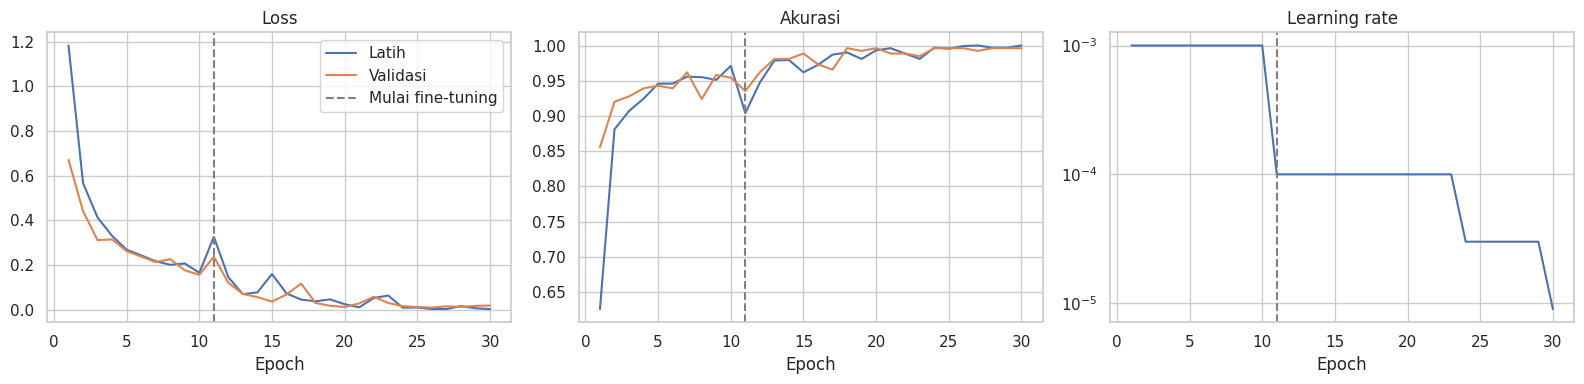

Gap akhir (acc latih - val): +0.0038


In [ ]:
# Kurva pembelajaran
h = main["history"]
p2_start = h.index[h.phase == 2][0] + 1 if (h.phase == 2).any() else None
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, k, t in zip(ax[:2], ["loss", "acc"], ["Loss", "Akurasi"]):
    a.plot(h.epoch, h[f"train_{k}"], label="Latih"); a.plot(h.epoch, h[f"val_{k}"], label="Validasi")
    a.set(title=t, xlabel="Epoch")
ax[2].semilogy(h.epoch, h.lr); ax[2].set(title="Learning rate", xlabel="Epoch")
for a in ax:
    if p2_start: a.axvline(p2_start, color="gray", ls="--", label="Mulai fine-tuning")
ax[0].legend(); plt.tight_layout(); savefig("04_kurva_training"); plt.show()
h.to_csv(OUT / "history.csv", index=False)
print(f"Gap akhir (acc latih - val): {h.train_acc.iloc[-1] - h.val_acc.iloc[-1]:+.4f}")

In [ ]:
# Evaluasi test set + CI bootstrap
model = main["model"]
test_dl = make_loader(test_ds, False, cfg.seed)
y_test, probs_test = predict(model, test_dl)
pred_test = probs_test.argmax(1)


def ece_score(y, probs, bins=15):
    """Expected Calibration Error."""
    conf, correct = probs.max(1), (probs.argmax(1) == y).astype(float)
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e


metric_fns = {"accuracy": accuracy_score, "balanced_acc": balanced_accuracy_score,
              "f1_macro": lambda a, b: f1_score(a, b, average="macro"), "mcc": matthews_corrcoef}
point = summarize(y_test, probs_test)
rng = np.random.default_rng(cfg.seed)
boot_idx = rng.integers(0, len(y_test), (cfg.n_boot, len(y_test)))
ci = {k: np.percentile([f(y_test[i], pred_test[i]) for i in boot_idx], [2.5, 97.5])
      for k, f in metric_fns.items()}

test_metrics = {**point, "roc_auc_macro_ovr": roc_auc_score(y_test, probs_test, multi_class="ovr", average="macro"),
                "ece": ece_score(y_test, probs_test)}
tbl = pd.DataFrame({"nilai": test_metrics})
tbl["CI95_low"] = pd.Series({k: v[0] for k, v in ci.items()})
tbl["CI95_high"] = pd.Series({k: v[1] for k, v in ci.items()})
print(tbl.round(4).to_string(), "\n")

report = classification_report(y_test, pred_test, target_names=class_names, digits=4, output_dict=True, zero_division=0)
print(classification_report(y_test, pred_test, target_names=class_names, digits=4, zero_division=0))
tbl.to_csv(OUT / "test_metrics.csv"); pd.DataFrame(report).T.to_csv(OUT / "test_classification_report.csv")

                    nilai  CI95_low  CI95_high
accuracy           0.9925    0.9813        1.0
balanced_acc       0.9857    0.9639        1.0
precision_macro    0.9887       NaN        NaN
recall_macro       0.9857       NaN        NaN
f1_macro           0.9871    0.9665        1.0
mcc                0.9907    0.9766        1.0
roc_auc_macro_ovr  0.9999       NaN        NaN
ece                0.0083       NaN        NaN 

                      precision    recall  f1-score   support

      Bacterial Spot     0.9474    0.9474    0.9474        19
Cercospora Leaf Spot     1.0000    0.9667    0.9831        30
          Curl Virus     1.0000    1.0000    1.0000        61
        Healthy Leaf     1.0000    1.0000    1.0000        65
Nutrition Deficiency     0.9848    1.0000    0.9924        65
          White spot     1.0000    1.0000    1.0000        27

            accuracy                         0.9925       267
           macro avg     0.9887    0.9857    0.9871       267
        weighte

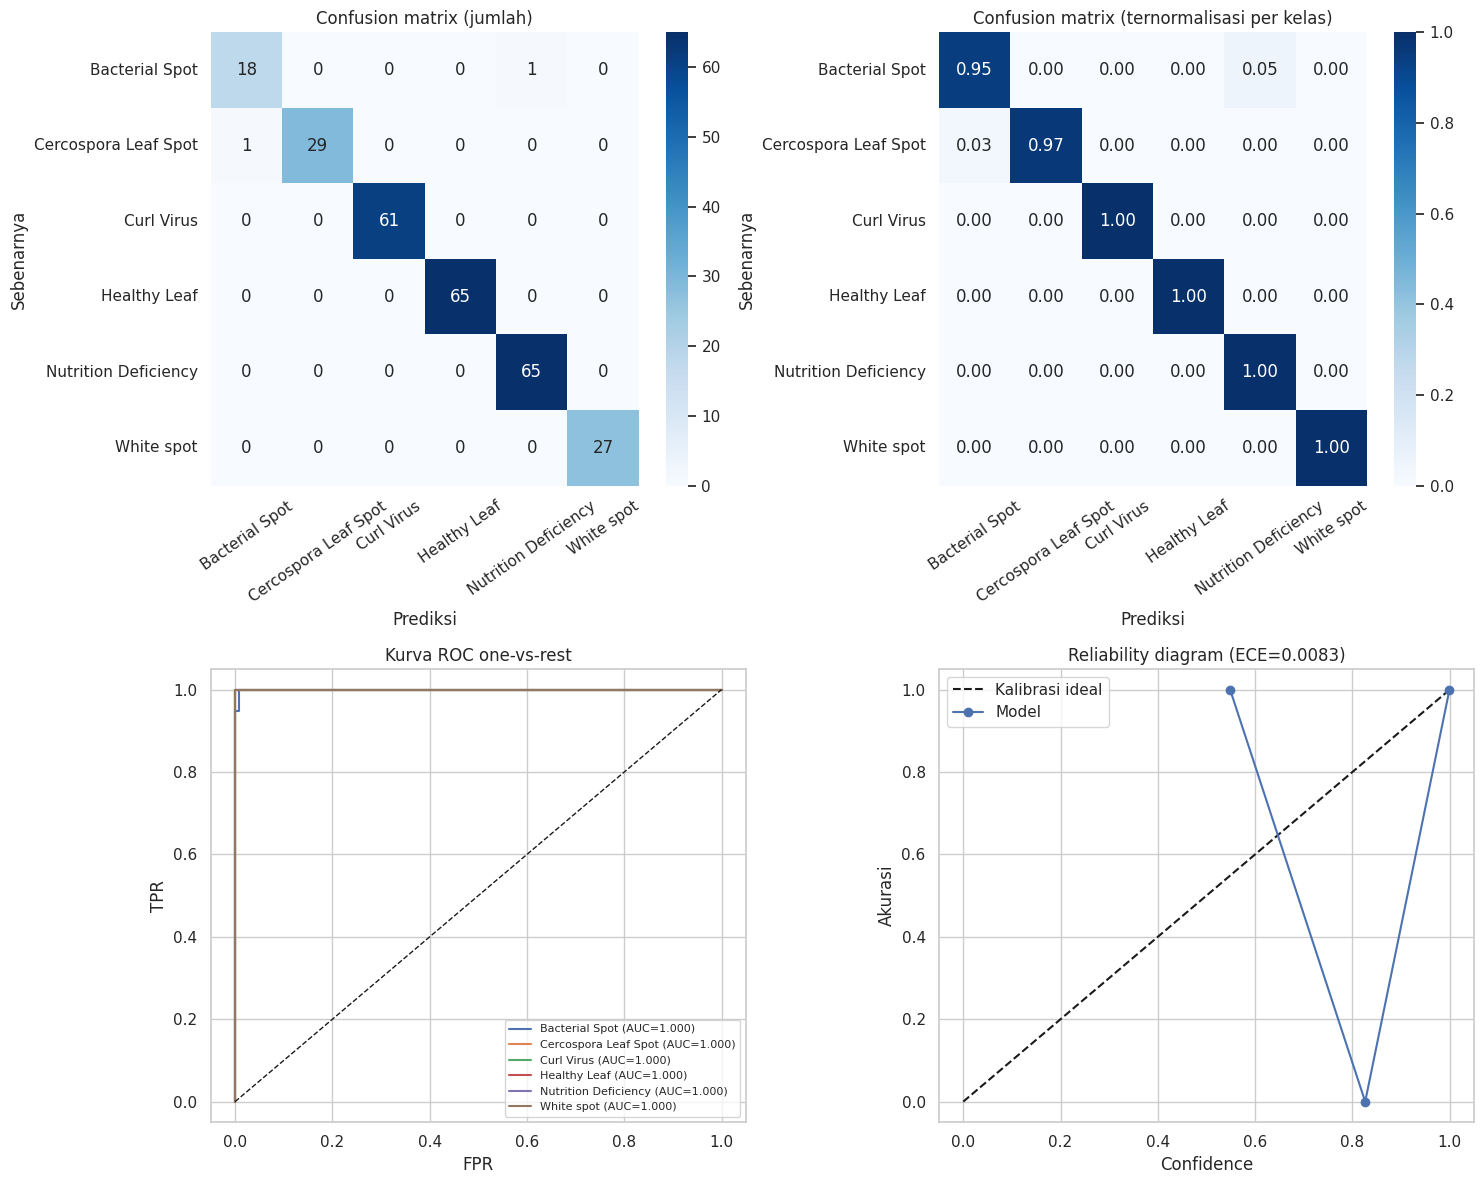

In [ ]:
# ===== Cell 13: Visualisasi evaluasi =====
cm = confusion_matrix(y_test, pred_test, labels=np.arange(NUM_CLASSES))
cm_n = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(2, 2, figsize=(15, 12))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0, 0])
ax[0, 0].set_title("Confusion matrix (jumlah)")
sns.heatmap(cm_n, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0, 1])
ax[0, 1].set_title("Confusion matrix (ternormalisasi per kelas)")
for a in ax[0]:
    a.set(xlabel="Prediksi", ylabel="Sebenarnya"); a.tick_params(axis="x", rotation=35)

yb = label_binarize(y_test, classes=np.arange(NUM_CLASSES))
for k, c in enumerate(class_names):
    fpr, tpr, _ = roc_curve(yb[:, k], probs_test[:, k])
    ax[1, 0].plot(fpr, tpr, label=f"{c} (AUC={roc_auc_score(yb[:, k], probs_test[:, k]):.3f})")
ax[1, 0].plot([0, 1], [0, 1], "k--", lw=1)
ax[1, 0].set(title="Kurva ROC one-vs-rest", xlabel="FPR", ylabel="TPR"); ax[1, 0].legend(fontsize=8)

conf, corr = probs_test.max(1), (pred_test == y_test).astype(float)
edges = np.linspace(0, 1, 11); mc, ac = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.any(): mc.append(conf[m].mean()); ac.append(corr[m].mean())
ax[1, 1].plot([0, 1], [0, 1], "k--", label="Kalibrasi ideal"); ax[1, 1].plot(mc, ac, "o-", label="Model")
ax[1, 1].set(title=f"Reliability diagram (ECE={test_metrics['ece']:.4f})", xlabel="Confidence", ylabel="Akurasi")
ax[1, 1].legend()
plt.tight_layout(); savefig("05_evaluasi_test"); plt.show()

Salah prediksi: 2/267
 Bacterial Spot -> Nutrition Deficiency    1
Cercospora Leaf Spot -> Bacterial Spot    1


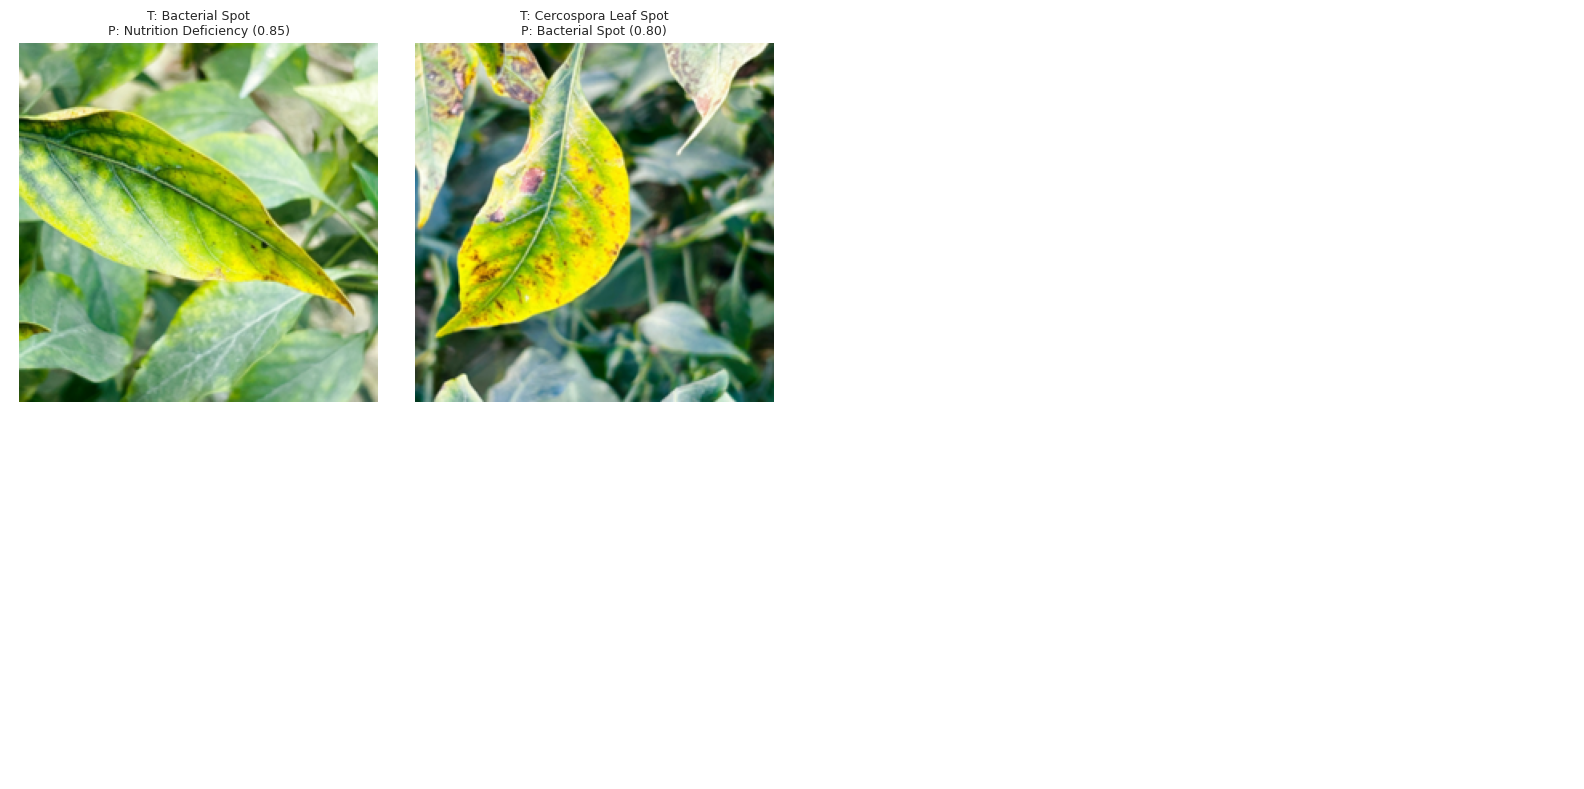

In [ ]:
# Analisis kesalahan prediksi
err = np.where(pred_test != y_test)[0]
pairs = (pd.Series([f"{class_names[y_test[i]]} -> {class_names[pred_test[i]]}" for i in err])
         .value_counts().rename("jumlah"))
print(f"Salah prediksi: {len(err)}/{len(y_test)}\n", pairs.to_string())
pairs.to_csv(OUT / "pasangan_kesalahan.csv")

top_err = err[np.argsort(-probs_test[err].max(1))][:8]        # kesalahan dengan confidence tertinggi
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.ravel(), top_err):
    ax.imshow(test_imgs[i].resize((cfg.img_size,) * 2))
    ax.set_title(f"T: {class_names[y_test[i]]}\nP: {class_names[pred_test[i]]} ({probs_test[i].max():.2f})", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); savefig("06_galeri_error"); plt.show()

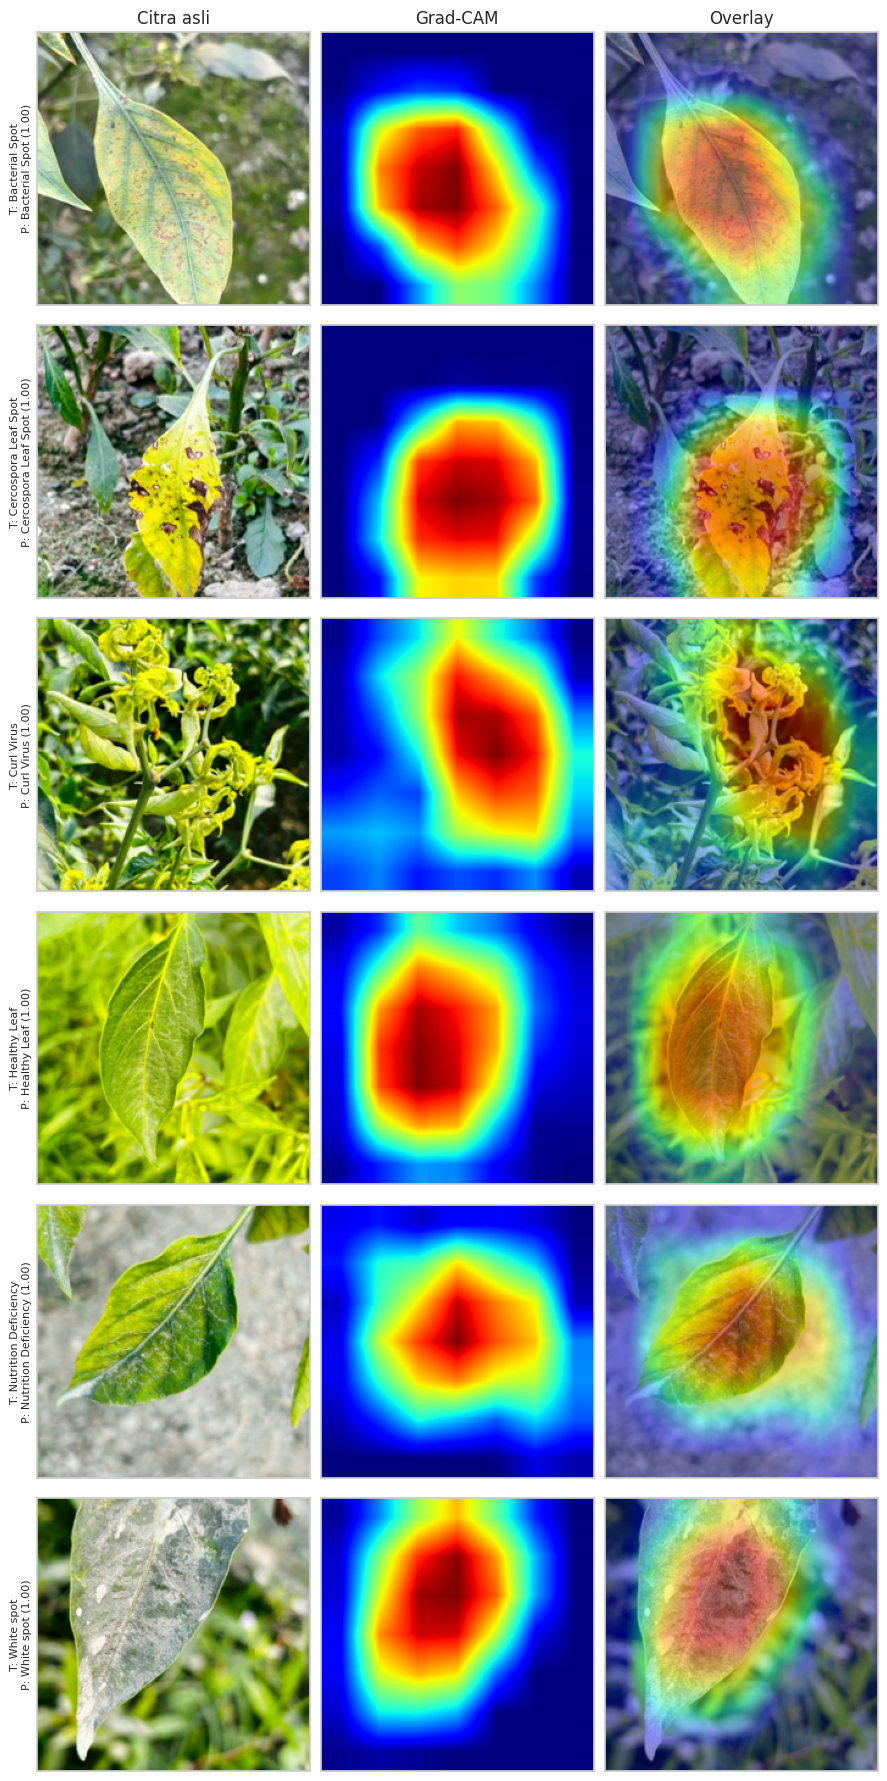

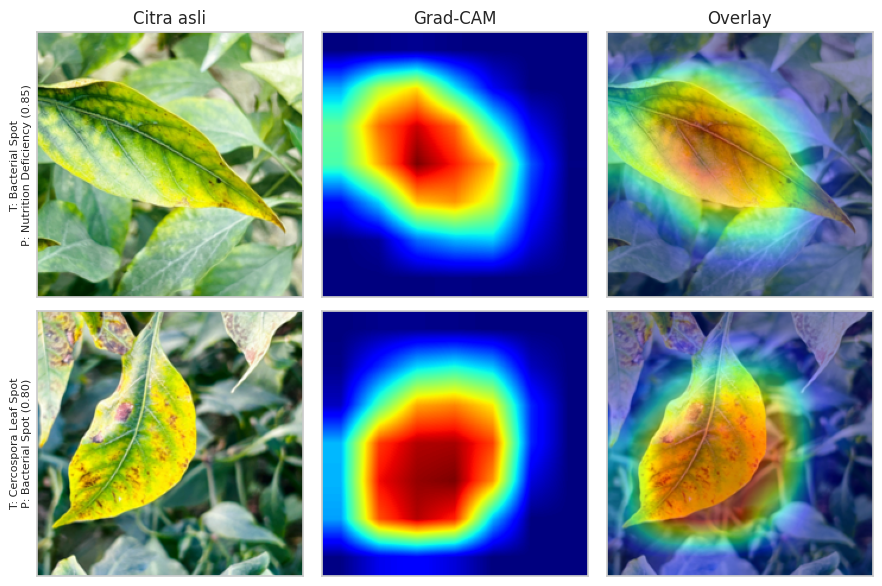

In [ ]:
# ===== Cell 15: Grad-CAM (analisis peta perhatian) =====
class GradCAM:
    """Grad-CAM pada keluaran fitur terakhir MobileNetV2 (peta 7x7, di-upsample)."""
    def __init__(self, model): self.model = model.eval()

    def __call__(self, x, target=None):
        with torch.enable_grad():
            feats = self.model.features(x).detach().requires_grad_(True)
            logits = self.model.classifier(F.adaptive_avg_pool2d(feats, 1).flatten(1))
            target = logits.argmax(1) if target is None else target
            grads = torch.autograd.grad(logits.gather(1, target[:, None]).sum(), feats)[0]
        w = grads.mean((2, 3), keepdim=True)
        cam = F.relu((w * feats).sum(1, keepdim=True)).detach()
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = (cam - cam.amin((2, 3), keepdim=True)) / (cam.amax((2, 3), keepdim=True) - cam.amin((2, 3), keepdim=True) + 1e-8)
        return cam.squeeze(1).cpu().numpy(), F.softmax(logits.detach(), 1).cpu().numpy()


gradcam = GradCAM(model)


def show_cam(indices, fname):
    """Kolom: citra asli | heatmap | overlay."""
    fig, axes = plt.subplots(len(indices), 3, figsize=(9, 3 * len(indices)))
    axes = np.atleast_2d(axes)
    for row, i in zip(axes, indices):
        x = eval_tf(test_imgs[i]).unsqueeze(0).to(DEVICE)
        cam, pr = gradcam(x)
        img = np.asarray(test_imgs[i].resize((cfg.img_size,) * 2)) / 255.0
        heat = plt.get_cmap("jet")(cam[0])[..., :3]
        row[0].imshow(img); row[1].imshow(cam[0], cmap="jet"); row[2].imshow(0.55 * img + 0.45 * heat)
        row[0].set_ylabel(f"T: {class_names[y_test[i]]}\nP: {class_names[pr[0].argmax()]} ({pr[0].max():.2f})", fontsize=8)
        for a in row: a.set_xticks([]); a.set_yticks([])
    for a, t in zip(axes[0], ["Citra asli", "Grad-CAM", "Overlay"]): a.set_title(t)
    plt.tight_layout(); savefig(fname); plt.show()


# prediksi benar dengan confidence tertinggi per kelas
correct_idx = []
for k in range(NUM_CLASSES):
    m = np.where((y_test == k) & (pred_test == k))[0]
    if len(m): correct_idx.append(m[np.argmax(probs_test[m, k])])
show_cam(correct_idx, "07_gradcam_benar")
if len(err): show_cam(top_err[:4], "08_gradcam_salah")

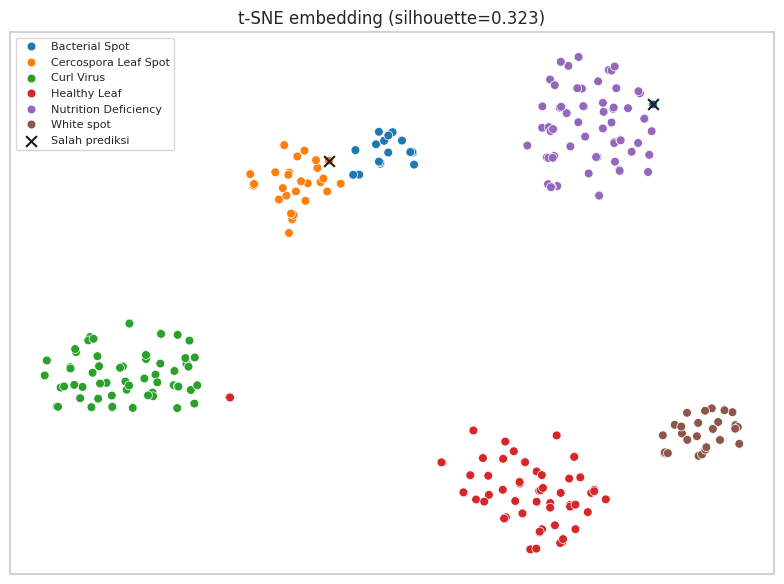

In [ ]:
# ===== Cell 16: t-SNE embedding GAP (1280-d) pada data uji =====
@torch.no_grad()
def extract_embeddings(model, loader):
    model.eval()
    return torch.cat([F.adaptive_avg_pool2d(model.features(x.to(DEVICE)), 1).flatten(1).cpu()
                      for x, _ in loader]).numpy()


emb = extract_embeddings(model, test_dl)                      # urutan sama dengan test_df
sil = silhouette_score(emb, y_test)
xy = TSNE(n_components=2, perplexity=30, init="pca", random_state=cfg.seed).fit_transform(emb)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=[class_names[i] for i in y_test], palette="tab10", s=40, ax=ax)
ax.scatter(xy[err, 0], xy[err, 1], marker="x", c="k", s=60, label="Salah prediksi")
ax.set(title=f"t-SNE embedding (silhouette={sil:.3f})", xticks=[], yticks=[]); ax.legend(fontsize=8)
plt.tight_layout(); savefig("09_tsne"); plt.show()

In [ ]:
# Kompleksitas & kecepatan inferensi
from torch.utils.flop_counter import FlopCounterMode

S = cfg.img_size


def latency_ms(m, device, bs=1, runs=100, warm=20):
    m = m.to(device).eval(); x = torch.randn(bs, 3, S, S, device=device)
    sync = (lambda: torch.cuda.synchronize()) if device.type == "cuda" else (lambda: None)
    ts = []
    with torch.inference_mode():
        for _ in range(warm): m(x)
        sync()
        for _ in range(runs):
            t = time.perf_counter(); m(x); sync(); ts.append((time.perf_counter() - t) * 1e3)
    return float(np.median(ts)), float(np.percentile(ts, 95))


cpu_model = copy.deepcopy(model).cpu().eval()
buf = io.BytesIO(); torch.save(model.state_dict(), buf)
with FlopCounterMode(display=False) as fc, torch.inference_mode():
    cpu_model(torch.randn(1, 3, S, S))

eff = {"params_juta": count_params(model)[0] / 1e6, "ukuran_mb": buf.tell() / 1e6,
       "gflops_per_citra": fc.get_total_flops() / 1e9, "threads_cpu": torch.get_num_threads()}
eff["cpu_b1_median_ms"], eff["cpu_b1_p95_ms"] = latency_ms(cpu_model, torch.device("cpu"))
if USE_AMP:
    eff["gpu_b1_median_ms"], eff["gpu_b1_p95_ms"] = latency_ms(model, DEVICE)
    eff["gpu_b32_throughput_img_s"] = 32 / latency_ms(model, DEVICE, bs=32, runs=50)[0] * 1e3
eff["waktu_latih_menit"] = main["minutes"]
print(pd.Series(eff).round(3).to_string())

params_juta                    2.232
ukuran_mb                      9.170
gflops_per_citra               0.599
threads_cpu                    2.000
cpu_b1_median_ms              20.666
cpu_b1_p95_ms                 22.446
gpu_b1_median_ms               5.009
gpu_b1_p95_ms                  5.567
gpu_b32_throughput_img_s    1022.796
waktu_latih_menit              1.844


In [ ]:
# ===== Cell 18: Simpan model, konfigurasi, dan log =====
torch.save({"state_dict": model.state_dict(), "class_names": class_names, "cfg": asdict(cfg),
            "normalize": {"mean": MEAN, "std": STD}}, OUT / "mobilenetv2_chili.pt")

pd.concat([train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")]
          ).drop(columns=["md5"]).to_csv(OUT / "split_data.csv", index=False)
split_summary.to_csv(OUT / "ringkasan_split.csv")

with open(OUT / "run_summary.json", "w") as f:
    json.dump({"env": ENV, "cfg": asdict(cfg), "cleaning": clean_log, "class_names": class_names,
               "val_metrics": main["val"], "test_metrics": {k: float(v) for k, v in test_metrics.items()},
               "efficiency": eff}, f, indent=2, default=float)

for p in sorted(OUT.glob("*.*")):
    print(f"{p.name:<32}{p.stat().st_size / 1e6:8.2f} MB")

.virtual_documents                  0.00 MB
ablation_val.csv                    0.00 MB
history.csv                         0.00 MB
mobilenetv2_chili.pt                9.17 MB
mobilenetv2_chili.pth               9.17 MB
pasangan_kesalahan.csv              0.00 MB
ringkasan_split.csv                 0.00 MB
run_summary.json                    0.00 MB
split_data.csv                      0.31 MB
test_classification_report.csv      0.00 MB
test_metrics.csv                    0.00 MB
